## **Parallel Workflows by showing an example of Cricket**

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [7]:
class BatsmanState(TypedDict):
    ## input variables
    runs: int
    balls: int
    fours: int
    sixes: int

    ## Calculated variables
    sr: float
    bpb: float
    boundary_percent: float
    summary: str

In [24]:
## Strikerate Code

def calculate_strikerate(state: BatsmanState) -> BatsmanState:
    ## Retrieve no of Balls, and runs
    strike_rate = (state["runs"] / state["balls"]) * 100

    return {"sr": strike_rate}



In [25]:
## Balls Per Boundary Code
def calculate_balls_per_boundary(state: BatsmanState) -> BatsmanState:
    ## retrieve balls, fours, sixes
    balls_per_boundary = state["balls"] / (state["fours"] + state["sixes"])

    return {"bpb": balls_per_boundary}


In [26]:
## Batsman's Boundary percentage
def calculate_boundary_percentage(state: BatsmanState) -> BatsmanState:
    ## Retrieve fours, sixes
    boundary = (((state["fours"] * 4)  +  (state["sixes"] * 6)) / state["runs"]) * 100

    return {"boundary_percent": boundary}

In [27]:
## summary
def summary(state: BatsmanState) -> BatsmanState:
    summary = f"""
        Strike Rate - {state['sr']} \n
        Balls per boundary - {state['bpb']} \n
        Boundary percent - {state['boundary_percent']}
    """

    return {"summary": summary}

In [28]:
graph = StateGraph(BatsmanState)

## add nodes
graph.add_node("calculate_strikerate", calculate_strikerate)
graph.add_node("calculate_balls_per_boundary", calculate_balls_per_boundary)
graph.add_node("calculate_boundary_percentage", calculate_boundary_percentage)
graph.add_node("summary", summary)

## add edges

### Parallel Edges
graph.add_edge(START, "calculate_strikerate")
graph.add_edge(START, "calculate_balls_per_boundary")
graph.add_edge(START, "calculate_boundary_percentage")

## Parallel Combined Edges
graph.add_edge("calculate_strikerate", "summary")
graph.add_edge("calculate_balls_per_boundary", "summary")
graph.add_edge("calculate_boundary_percentage", "summary")

graph.add_edge("summary", END)


## Compile the graph
workflow = graph.compile()

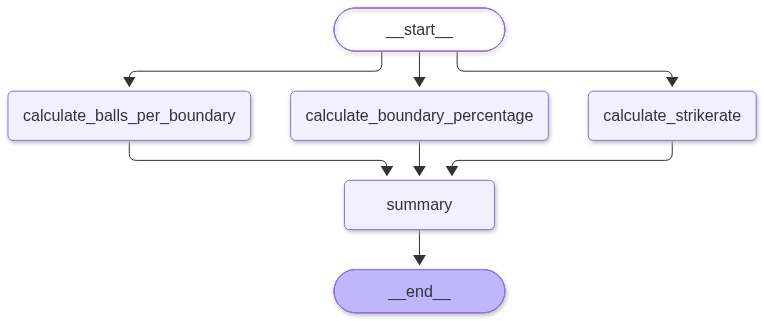

In [29]:
workflow

In [30]:
initial_state = {
    "runs": 100,
    "balls": 50,
    "fours": 6,
    "sixes": 4,
}

results = workflow.invoke(initial_state)

In [31]:
print(results)

{'runs': 100, 'balls': 50, 'fours': 6, 'sixes': 4, 'sr': 200.0, 'bpb': 5.0, 'boundary_percent': 48.0, 'summary': '\n        Strike Rate - 200.0 \n\n        Balls per boundary - 5.0 \n\n        Boundary percent - 48.0\n    '}


In [32]:
print(f"""
🏏 Batting Performance Summary
------------------------------
Total Runs          : {results['runs']}
Balls Faced         : {results['balls']}
Fours               : {results['fours']}
Sixes               : {results['sixes']}
Strike Rate         : {results['sr']}
Balls Per Boundary  : {results['bpb']}
Boundary Percentage : {results['boundary_percent']}%
""")


🏏 Batting Performance Summary
------------------------------
Total Runs          : 100
Balls Faced         : 50
Fours               : 6
Sixes               : 4
Strike Rate         : 200.0
Balls Per Boundary  : 5.0
Boundary Percentage : 48.0%



In [34]:
from pprint import pprint

pprint(results, sort_dicts=False)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\n'
            '        Strike Rate - 200.0 \n'
            '\n'
            '        Balls per boundary - 5.0 \n'
            '\n'
            '        Boundary percent - 48.0\n'
            '    '}


In [35]:
import json

results = workflow.invoke(initial_state)

print(json.dumps(results, indent=4, ensure_ascii=False))

{
    "runs": 100,
    "balls": 50,
    "fours": 6,
    "sixes": 4,
    "sr": 200.0,
    "bpb": 5.0,
    "boundary_percent": 48.0,
    "summary": "\n        Strike Rate - 200.0 \n\n        Balls per boundary - 5.0 \n\n        Boundary percent - 48.0\n    "
}


In [36]:
from pprint import pprint

results = workflow.invoke(initial_state)

pprint(results, sort_dicts=False)

print("\nActual Summary:")
print(results["summary"])

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\n'
            '        Strike Rate - 200.0 \n'
            '\n'
            '        Balls per boundary - 5.0 \n'
            '\n'
            '        Boundary percent - 48.0\n'
            '    '}

Actual Summary:

        Strike Rate - 200.0 

        Balls per boundary - 5.0 

        Boundary percent - 48.0
    
